In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')
path_tcc = '/content/drive/MyDrive/TCC_DCGAN'
os.chdir(path_tcc)
print(f"Diretório atual: {os.getcwd()}")
!ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Diretório atual: /content/drive/MyDrive/TCC_DCGAN
 __1_fid_evolution_results
 1_matriz__confusao_a.png
 1_matriz__confusao_baseline.png
 1_matriz__confusao_b.png
 1_test_model_B_500_epochs_Late_blight_8x8_base_128x128.html
 2_matriz_confusao_a.png
 2_matriz_confusao_baseline.png
 2_matriz_confusao_b.png
 checkpoints.zip
 config
 cria_augment_datasets.py
 dataset
 dataset.py
 datasets_aumentados
 _datasets_aumentados_v_final
 _evolucao_fid_comparativo_classes.png
 evolucao_fid_comparativo_classes.png
 experiments
 fid_batches_melhores_epocas
 fid_evolution_results
 fid.py
 final_mobilenetv2_a.h5
 final_mobilenetv2_baseline.h5
 final_mobilenetv2_b.h5
 generate_image.py
 gerar_grafico_2.py
 _grafico_comparativo_healthy.html
 grafico_comparativo_healthy.html
 _grafico_comparativo_Late_blight.html
 grafico_comparativo_Late_blight.html
 _grafico_comparativo_powdery

In [ ]:
import os
project_path = '/content/drive/MyDrive/TCC_DCGAN'
os.chdir(project_path)
print(f"Diretório atual: {os.getcwd()}")

# !python train.py
!python train_model_b.py
# !python plot_graph.py
# !python cria_augment_datasets.py
# !python generate_image.py

# !python mobilenetv2.py
# !python gerar_grafico_2.py

Diretório atual: /content/drive/MyDrive/TCC_DCGAN
2026-06-09 12:25:37.995896: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-09 12:25:38.059909: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Carregando e preparando o dataset

dataset/train/powdery_mildew

Found 1004 files.
2026-06-09 12:25:43.293726: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1781007943.29

In [4]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import model_128 as model # Importa a sua arquitetura
import gc

# Configurações globais de exibição
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
tf.get_logger().setLevel('ERROR')

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

# --- CONFIGURAÇÕES DO QUADRO ---
EPOCHS_TO_PLOT = [10, 100, 250, 390, 500]
CLASSES = ["healthy", "Late_blight", "powdery_mildew"]
TITULOS_CLASSES = ["Healthy", "Late Blight", "Powdery Mildew"]

DIRETORIOS = {
    "Modelo_A": {
        "healthy": "__model_A_healthy_with_new_metrics",
        "Late_blight": "__model_A_Late_blight_with_new_metrics",
        "powdery_mildew": "__model_A_powdery_mildew_with_new_metrics"
    },
    "Modelo_B": {
        "healthy": "__model_B_healthy_with_new_metrics",
        "Late_blight": "__model_B_Late_blight_with_new_metrics",
        "powdery_mildew": "__model_B_powdery_mildew_with_new_metrics"
    }
}

NOISE_DIM = 100
BASE_DIR = "experiments"
plt.rcParams['font.family'] = 'serif'

# Semente fixa de 9 vetores (3x3) para garantir que a mesma folha seja acompanhada ao longo do tempo
SEED = tf.random.normal([9, NOISE_DIM])

def plot_evolution_from_checkpoints(modelo_nome, dict_classes):
    print(f"\nMontando quadro de evolução para o {modelo_nome.replace('_', ' ')}...")

    # Cria uma figura grande
    fig = plt.figure(figsize=(14, 18))
    fig.suptitle(f"Evolução Temporal da Síntese - {modelo_nome.replace('_', ' ')}", fontsize=20, y=0.95)

    # Grid externo: 4 Linhas (Épocas) x 3 Colunas (Classes)
    outer_gs = gridspec.GridSpec(len(EPOCHS_TO_PLOT), len(CLASSES), wspace=0.1, hspace=0.15)

    for row_idx, epoch in enumerate(EPOCHS_TO_PLOT):
        ckpt_num = epoch // 10 # Converte Época 100 para ckpt-10

        for col_idx, classe in enumerate(CLASSES):
            # Cria um Grid interno de 3x3 dentro da célula atual
            inner_gs = outer_gs[row_idx, col_idx].subgridspec(3, 3, wspace=0.05, hspace=0.05)

            caminho_ckpt = os.path.join(BASE_DIR, dict_classes[classe], "checkpoints", f"ckpt-{ckpt_num}")

            # Instancia gerador e restaura pesos
            generator = model.make_generator_model()
            ckpt = tf.train.Checkpoint(generator=generator)

            imagens_geradas = None
            try:
                ckpt.restore(caminho_ckpt).expect_partial()
                # Passa a SEED fixa pelo gerador
                pred = generator(SEED, training=False)
                # Converte os tensores de [-1, 1] (saída da Tanh) para pixels [0, 1]
                imagens_geradas = (pred.numpy() + 1.0) / 2.0
            except Exception as e:
                print(f"  Aviso: Não foi possível carregar Época {epoch} da classe {classe}.")

            # Plota as 9 imagens no subgrid interno 3x3
            for i in range(9):
                ax = fig.add_subplot(inner_gs[i // 3, i % 3])
                ax.set_xticks([])
                ax.set_yticks([])

                # Remove as bordas pretas de cada imagem
                for spine in ax.spines.values():
                    spine.set_visible(False)

                if imagens_geradas is not None:
                    ax.imshow(imagens_geradas[i])
                else:
                    ax.set_facecolor('#f0f0f0') # Fundo cinza se der erro
                    if i == 4: # No quadrado central
                        ax.text(0.5, 0.5, f"Sem\nDados", ha='center', va='center', color='red', fontsize=10)

                # Coloca Título da Coluna (Classe) na primeira linha, imagem do topo-centro (i=1)
                if row_idx == 0 and i == 1:
                    ax.set_title(TITULOS_CLASSES[col_idx], fontsize=16, pad=15)

                # Coloca Título da Linha (Época) na primeira coluna, imagem do meio-esquerda (i=3)
                if col_idx == 0 and i == 3:
                    ax.set_ylabel(f"Época {epoch}", fontsize=16, labelpad=20, fontweight='bold')

        # Limpa memória a cada linha processada
        tf.keras.backend.clear_session()
        gc.collect()

    nome_saida = f"1finalquadro_evolucao_3x3_{modelo_nome.lower()}.png"
    plt.savefig(nome_saida, dpi=300, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"✔ Imagem salva com sucesso: {nome_saida}")

# --- EXECUÇÃO ---
if __name__ == '__main__':
    for modelo, classes in DIRETORIOS.items():
        plot_evolution_from_checkpoints(modelo, classes)
    print("\nProcesso finalizado! As duas imagens de alta resolução estão prontas para o TCC.")


Montando quadro de evolução para o Modelo A...
✔ Imagem salva com sucesso: 1finalquadro_evolucao_3x3_modelo_a.png

Montando quadro de evolução para o Modelo B...
✔ Imagem salva com sucesso: 1finalquadro_evolucao_3x3_modelo_b.png

Processo finalizado! As duas imagens de alta resolução estão prontas para o TCC.


In [ ]:
import os
from pathlib import Path

PATH_RAIZ = Path("_datasets_aumentados_v_final")
MODELOS = ["A", "B"]
CLASSES = ["Late_blight", "healthy", "powdery_mildew"]

def contar_imagens():
    print("=========================================")
    print(" CONTAGEM DO DATASET AUMENTADO (FINAL)")
    print("=========================================\n")

    if not PATH_RAIZ.exists():
        print(f"Erro: A pasta {PATH_RAIZ} não foi encontrada.")
        return

    for modelo in MODELOS:
        total_modelo = 0
        print(f"Cenário - Modelo {modelo}:")

        for classe in CLASSES:
            pasta = PATH_RAIZ / modelo / classe

            if pasta.exists():
                # Conta apenas os arquivos reais (ignora subdiretórios se existirem)
                qtd_imagens = len([f for f in pasta.iterdir() if f.is_file()])
                print(f"  ├── {classe.ljust(15)} : {qtd_imagens} imagens")
                total_modelo += qtd_imagens
            else:
                print(f"  ├── {classe.ljust(15)} : [PASTA NÃO ENCONTRADA]")

        print(f"  └── TOTAL           : {total_modelo} imagens\n")

if __name__ == "__main__":
    contar_imagens()

 CONTAGEM DO DATASET AUMENTADO (FINAL)

Cenário - Modelo A:
  ├── Late_blight     : 3800 imagens
  ├── healthy         : 4000 imagens
  ├── powdery_mildew  : 4000 imagens
  └── TOTAL           : 11800 imagens

Cenário - Modelo B:
  ├── Late_blight     : 3800 imagens
  ├── healthy         : 4000 imagens
  ├── powdery_mildew  : 1405 imagens
  └── TOTAL           : 9205 imagens



In [ ]:
import os
import glob
import re
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.linalg import sqrtm
import time

# Configurações globais de exibição
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
tf.get_logger().setLevel('ERROR')

# Na A100, permitimos que a memória cresça conforme a necessidade
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


# --- CONFIGURAÇÕES DE DIRETÓRIOS ---
BASE_EXPERIMENTS_DIR = "experiments"
REAL_DATASET_ROOT = "dataset/train"
OUTPUT_CSV_DIR = "fid_evolution_results"

CLASS_SIZES = {
    "healthy": 3051,
    "Late_blight": 3113,
    "powdery_mildew": 1004
}

NOISE_DIM = 100
IMG_SHAPE = (128, 128, 3)
BATCH_SIZE = 512  # A100 aguenta perfeitamente lotes de 512 na memória

import model_128 as model

# --- FUNÇÕES NATIVAS IN-MEMORY ---

def preprocess_images(dataset):
    return dataset.map(lambda images: tf.keras.applications.inception_v3.preprocess_input(images))

def extrair_numero_checkpoint(nome_arquivo):
    match = re.search(r'ckpt-(\d+)', nome_arquivo)
    return int(match.group(1)) if match else None

def calcular_estatisticas_dataset_real(inception_model, path_imagens_reais):
    """Lê as imagens reais do disco uma vez, passa pelo Inception e devolve mu e sigma"""
    ds = tf.keras.utils.image_dataset_from_directory(
        path_imagens_reais, label_mode=None, image_size=IMG_SHAPE[:2], batch_size=BATCH_SIZE, verbose=False
    )
    ds_preprocessed = preprocess_images(ds).prefetch(tf.data.AUTOTUNE)

    act = inception_model.predict(ds_preprocessed, verbose=0)
    mu = act.mean(axis=0)
    sigma = np.cov(act, rowvar=False)
    return mu, sigma

def calcular_estatisticas_dataset_gerado(generator, inception_model, num_images):
    """Gera imagens na GPU e passa diretamente para o Inception sem gravar no disco"""
    acts = []
    num_batches = int(np.ceil(num_images / BATCH_SIZE))

    for i in range(num_batches):
        current_batch_size = min(BATCH_SIZE, num_images - i * BATCH_SIZE)
        noise = tf.random.normal([current_batch_size, NOISE_DIM])

        # O Gerador já devolve valores entre [-1, 1] (Tanh).
        # O InceptionV3 espera EXATAMENTE valores entre [-1, 1].
        # Portanto, ignoramos o disco e a etapa de pré-processamento, passando direto!
        gen_imgs = generator(noise, training=False)

        # Passar imagens geradas diretamente para o Inception
        act = inception_model(gen_imgs, training=False)
        acts.append(act.numpy())

    all_acts = np.concatenate(acts, axis=0)
    mu = all_acts.mean(axis=0)
    sigma = np.cov(all_acts, rowvar=False)
    return mu, sigma

def compute_fid_from_stats(mu1, sigma1, mu2, sigma2):
    ssdiff = np.sum((mu1 - mu2)**2.0)
    covmean = sqrtm(sigma1.dot(sigma2))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return ssdiff + np.trace(sigma1 + sigma2 - 2.0 * covmean)

# --- EXECUÇÃO PRINCIPAL (IN-MEMORY SUPER RÁPIDO) ---
if __name__ == '__main__':
    os.makedirs(OUTPUT_CSV_DIR, exist_ok=True)

    print("🚀 Iniciando pipeline In-Memory (Otimizado para A100)...")

    # Carrega o InceptionV3 apenas uma vez para a VRAM
    inception_model = tf.keras.applications.InceptionV3(
        include_top=False, pooling='avg', input_shape=IMG_SHAPE
    )

    # Filtro adaptado para garantir que apenas as pastas com o novo padrão sejam processadas
    pastas_experimentos = [d for d in os.listdir(BASE_EXPERIMENTS_DIR)
                           if os.path.isdir(os.path.join(BASE_EXPERIMENTS_DIR, d))
                           and d.startswith("__model_")]

    for pasta in pastas_experimentos:
        print(f"\n=======================================================")
        print(f"PROCESSANDO: {pasta}")
        print(f"=======================================================")

        # Identificação robusta do modelo A ou B
        if "__model_A" in pasta:
            modelo_tag = "Modelo_A"
        elif "__model_B" in pasta:
            modelo_tag = "Modelo_B"
        else:
            print(f"Ignorado: Modelo não identificado em '{pasta}'.")
            continue

        classe_alvo = next((c for c in CLASS_SIZES.keys() if c in pasta), None)
        if not classe_alvo:
            print(f"Ignorado: Classe não identificada em '{pasta}'.")
            continue

        num_imagens_gerar = CLASS_SIZES[classe_alvo]
        path_imagens_reais = os.path.join(REAL_DATASET_ROOT, classe_alvo)
        path_checkpoints = os.path.join(BASE_EXPERIMENTS_DIR, pasta, "checkpoints")

        if not os.path.exists(path_checkpoints):
            print(f"Ignorado: Sem checkpoints para '{pasta}'.")
            continue

        arquivos_index = glob.glob(os.path.join(path_checkpoints, "ckpt-*.index"))
        numeros_ckpt = sorted([extrair_numero_checkpoint(f) for f in arquivos_index if extrair_numero_checkpoint(f) is not None])

        if not numeros_ckpt:
            print(f"Nenhum checkpoint válido em '{pasta}'.")
            continue

        # 1. Pré-calcula as estatísticas REAIS UMA ÚNICA VEZ para esta classe
        print(f"A calcular matrizes reais para {classe_alvo} (só ocorre 1x)...")
        mu_real, sigma_real = calcular_estatisticas_dataset_real(inception_model, path_imagens_reais)

        historico_fid = []
        generator = model.make_generator_model()
        ckpt_loader = tf.train.Checkpoint(generator=generator)

        start_time_pasta = time.time()

        for num_ckpt in numeros_ckpt:
            época_equivalente = num_ckpt * 10
            caminho_prefixo_ckpt = os.path.join(path_checkpoints, f"ckpt-{num_ckpt}")

            try:
                ckpt_loader.restore(caminho_prefixo_ckpt).expect_partial()
            except Exception as e:
                continue

            try:
                # 2. Gera e calcula as estatísticas SINTÉTICAS diretamente na VRAM
                mu_gen, sigma_gen = calcular_estatisticas_dataset_gerado(generator, inception_model, num_imagens_gerar)

                # 3. Calcula o FID usando a matemática vetorial pura
                fid_score = compute_fid_from_stats(mu_real, sigma_real, mu_gen, sigma_gen)
                print(f"  -> Época {época_equivalente:03d} | FID: {fid_score:.2f}")

                historico_fid.append({"checkpoint": num_ckpt, "epoch": época_equivalente, "fid": fid_score})
            except Exception as e:
                print(f"  [Erro] Falha ao processar época {época_equivalente}: {e}")

        # Salva o CSV
        if historico_fid:
            df_resultado = pd.DataFrame(historico_fid)
            nome_csv_saida = os.path.join(OUTPUT_CSV_DIR, f"evolucao_fid_{modelo_tag}_{classe_alvo}.csv")
            df_resultado.to_csv(nome_csv_saida, index=False)
            tempo_total = time.time() - start_time_pasta
            print(f"✔ Concluído em {tempo_total:.1f}s. Guardado: {nome_csv_saida}")

    print("\n=======================================================")
    print("🚀 PIPELINE IN-MEMORY CONCLUÍDO COM SUCESSO!")
    print("=======================================================")

🚀 Iniciando pipeline In-Memory (Otimizado para A100)...
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step

PROCESSANDO: __model_B_powdery_mildew_with_new_metrics
A calcular matrizes reais para powdery_mildew (só ocorre 1x)...


/tmp/ipykernel_51454/1761064660.py:87: LinAlgWarning:

Matrix is singular. The result might be inaccurate or the array might not have a square root.



  -> Época 010 | FID: 3313.52
  -> Época 020 | FID: 2325.16
  -> Época 030 | FID: 3164.51
  -> Época 040 | FID: 2821.38
  -> Época 050 | FID: 3117.29
  -> Época 060 | FID: 2701.88
  -> Época 070 | FID: 2575.52
  -> Época 080 | FID: 2783.73
  -> Época 090 | FID: 2882.39
  -> Época 100 | FID: 2484.61
  -> Época 110 | FID: 2813.38
  -> Época 120 | FID: 2511.41
  -> Época 130 | FID: 2126.74
  -> Época 140 | FID: 1939.65
  -> Época 150 | FID: 2389.91
  -> Época 160 | FID: 2808.54
  -> Época 170 | FID: 1808.23
  -> Época 180 | FID: 1704.67
  -> Época 190 | FID: 1796.14
  -> Época 200 | FID: 1933.22
  -> Época 210 | FID: 1737.05
  -> Época 220 | FID: 1925.94
  -> Época 230 | FID: 1901.39
  -> Época 240 | FID: 1693.75
  -> Época 250 | FID: 1632.90
  -> Época 260 | FID: 2872.69
  -> Época 270 | FID: 1520.89
  -> Época 280 | FID: 1504.32
  -> Época 290 | FID: 1646.44
  -> Época 300 | FID: 1560.31
  -> Época 310 | FID: 1739.92
  -> Época 320 | FID: 1990.11
  -> Época 330 | FID: 1665.41
  -> Época

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# --- CONFIGURAÇÕES ACADÊMICAS DE PLOTAGEM ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12

CSV_DIR = "fid_evolution_results"

# Mapeamento exato das classes e títulos
CLASSES = {
    "Late_blight": "Late Blight",
    "healthy": "Healthy",
    "powdery_mildew": "Powdery Mildew"
}

# Definição visual estruturada para distinguir sempre A e B
MODELS = {
    "Modelo_A": {"label": "Modelo A (Baseline)", "color": "#1f77b4", "linewidth": 2.0},
    "Modelo_B": {"label": "Modelo B (Estabilizado)", "color": "#ffc107", "linewidth": 2.0}
}

# Criar a grade de gráficos (1 linha, 3 colunas), compartilhando o eixo Y para fácil comparação
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

# Iterar sobre cada classe para preencher seu respectivo subgráfico
for i, (cls_key, cls_title) in enumerate(CLASSES.items()):
    ax = axes[i]

    # Adicionar as curvas de ambos os modelos no mesmo gráfico
    for mod_key, config in MODELS.items():
        csv_path = os.path.join(CSV_DIR, f"evolucao_fid_{mod_key}_{cls_key}.csv")

        if os.path.exists(csv_path):
            df = pd.read_csv(csv_path)

            # Ordenar por época caso o CSV tenha ficado fora de ordem no processamento paralelo/sequencial
            df = df.sort_values(by='epoch')

            ax.plot(
                df['epoch'],
                df['fid'],
                label=config['label'],
                color=config['color'],
                linewidth=config['linewidth'],
                alpha=0.9
            )
        else:
            print(f"Aviso: Arquivo não encontrado - {csv_path}")

    # Formatação do Subgráfico
    ax.set_title(cls_title, fontsize=14, pad=10)
    ax.set_xlabel('Épocas', fontsize=12)

    # Apenas o primeiro gráfico exibe o título do eixo Y (já que os eixos são compartilhados)
    if i == 0:
        ax.set_ylabel('FID', fontsize=12)

    ax.grid(True, linestyle=':', alpha=0.7)
    ax.legend(loc='upper right', fontsize=10)

# Ajustar os espaços para não cortar textos
plt.tight_layout()

# Salvar como imagem de alta resolução pronta para o LaTeX
nome_saida = "_evolucao_fid_comparativo_classes.png"
plt.savefig(nome_saida, dpi=300)
plt.close()

print(f"Gráfico gerado com sucesso: {nome_saida}")

Gráfico gerado com sucesso: _evolucao_fid_comparativo_classes.png


In [ ]:
import os
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Diretório base
BASE_DIR = "experiments"

diretorios_experimentos = {
    "Modelo A (Baseline)": {
        "Late_blight": "__model_A_Late_blight_with_new_metrics",
        "healthy": "__model_A_healthy_with_new_metrics",
        "powdery_mildew": "__model_A_powdery_mildew_with_new_metrics"
    },
    "Modelo B (Estabilizado)": {
        "Late_blight": "__model_B_Late_blight_with_new_metrics",
        "healthy": "__model_B_powdery_mildew_with_new_metrics",
        "powdery_mildew": "__model_B_powdery_mildew_with_new_metrics"
    }
}

legenda_classes = {
    "Late_blight": "Late_blight",
    "healthy": "healthy",
    "powdery_mildew": "powdery_mildew"
}

cores_modelos = {
    "Modelo A (Baseline)": "rgba(31, 119, 180, 0.8)",
    "Modelo B (Estabilizado)": "rgba(255, 193, 7, 0.9)"
}

# Itera sobre cada classe para gerar um gráfico individual
for classe_key, classe_nome in legenda_classes.items():

    # Cria figura 2x1 (Gen Loss em cima, Disc Loss embaixo)
    fig = make_subplots(
        rows=2, cols=1,
        shared_xaxes=True,
        subplot_titles=("Generator Loss", "Discriminator Loss"),
        vertical_spacing=0.1
    )

    for tipo_modelo, classes_dict in diretorios_experimentos.items():
        path_to_csv = os.path.join(BASE_DIR, classes_dict[classe_key], "training_log.csv")

        if not os.path.exists(path_to_csv):
            print(f"Aviso: {path_to_csv} não encontrado. Pulando {tipo_modelo}.")
            continue

        df = pd.read_csv(path_to_csv)
        cor = cores_modelos[tipo_modelo]

        # 1. Curva do Gerador
        fig.add_trace(
            go.Scatter(
                x=df['epoch'], y=df['gen_loss'],
                mode='lines',
                name=tipo_modelo,
                line=dict(color=cor, width=2),
                legendgroup=tipo_modelo,
                showlegend=True
            ),
            row=1, col=1
        )

        # 2. Curva do Discriminador
        fig.add_trace(
            go.Scatter(
                x=df['epoch'], y=df['disc_loss'],
                mode='lines',
                name=tipo_modelo,
                line=dict(color=cor, width=2),
                legendgroup=tipo_modelo,
                showlegend=False
            ),
            row=2, col=1
        )

    # Formatação
    fig.update_layout(
        title={
            'text': f'Comparação de Desempenho - Classe: {classe_nome}',
            'y': 0.95, 'x': 0.5, 'xanchor': 'center', 'yanchor': 'top'
        },
        template='plotly_white',
        font_family="Times New Roman",
        width=900,
        height=700,
        legend=dict(
            orientation="h", yanchor="top", y=-0.1, xanchor="center", x=0.5, font_size=14
        )
    )

    # Ajuste de eixos
    fig.update_xaxes(title_text="Época", title_font_size=14, tickfont_size=11, row=2, col=1)
    fig.update_yaxes(title_text="Loss", title_font_size=14, tickfont_size=11)

    for annotation in fig['layout']['annotations']:
        annotation['font'] = dict(size=14, family="Times New Roman")

    # Salva o arquivo HTML individual da classe
    nome_saida_html = f"_grafico_comparativo_{classe_key}.html"
    fig.write_html(nome_saida_html)
    print(f"Sucesso: Gráfico salvo como '{nome_saida_html}'.")

Sucesso: Gráfico salvo como '_grafico_comparativo_Late_blight.html'.
Sucesso: Gráfico salvo como '_grafico_comparativo_healthy.html'.
Sucesso: Gráfico salvo como '_grafico_comparativo_powdery_mildew.html'.


In [ ]:
import os
import pandas as pd
import plotly.graph_objects as go

base_dir = "experiments"
# Assumindo que o segundo powdery_mildew do modelo B na sua mensagem era um erro de digitação para healthy
categories = ["Late_blight", "healthy", "powdery_mildew"]

for category in categories:
    # Constrói os caminhos para os arquivos CSV
    file_A = os.path.join(base_dir, f"__model_A_{category}_with_new_metrics", "training_log.csv")
    file_B = os.path.join(base_dir, f"__model_B_{category}_with_new_metrics", "training_log.csv")

    fig = go.Figure()

    # Processa o log do Modelo A
    if os.path.exists(file_A):
        df_A = pd.read_csv(file_A)
        fig.add_trace(go.Scatter(
            x=df_A['epoch'],
            y=df_A['gen_grad_norm'],
            mode='lines',
            name=f'Model A ({category})',
            line=dict(color='blue')
        ))
    else:
        print(f"Arquivo não encontrado: {file_A}")

    # Processa o log do Modelo B
    if os.path.exists(file_B):
        df_B = pd.read_csv(file_B)
        fig.add_trace(go.Scatter(
            x=df_B['epoch'],
            y=df_B['gen_grad_norm'],
            mode='lines',
            name=f'Model B ({category})',
            line=dict(color='#ffc107')
        ))
    else:
        print(f"Arquivo não encontrado: {file_B}")

    # Formata e exibe o gráfico se houver dados
    if len(fig.data) > 0:
        fig.update_layout(
            title=f'Valores de Gradiente do Gerador: Model A vs Model B ({category})',
            xaxis_title='Epoch',
            yaxis_title='Generator Gradient',
            template='plotly_white',
            hovermode='x unified'
        )
        fig.show()

In [ ]:
import tensorflow as tf
import os

diretorio = '/content/drive/MyDrive/TCC_DCGAN/images_to_plot'
classes = ['healthy.JPG', 'Late_Blight.JPG', 'powdery_mildew.jpg']
noise_inicial = 0.2

for classe in classes:
    print(f"Processando: {classe}...")
    caminho_imagem = os.path.join(diretorio, classe)
    image_raw = tf.io.read_file(caminho_imagem)
    image = tf.image.decode_image(image_raw, channels=3)

    # 1. PRÉ-PROCESSAMENTO EXATAMENTE IGUAL AO SEU TREINAMENTO
    image = tf.image.resize(image, [128, 128])
    image = tf.cast(image, tf.float32)
    image = (image - 127.5) / 127.5 # A imagem agora está na escala [-1, 1]

    # Pega o nome sem a extensão para não sobrescrever os arquivos
    nome_base = classe.split('.')[0]

    for i in range(0, 301, 50):
        # Calcula o desvio padrão do ruído
        noise_stddev = noise_inicial * (1.0 - (i/300.0))

        # 2. APLICA O RUÍDO (Na escala [-1, 1], igual no seu train_step)
        ruido = tf.random.normal(shape=tf.shape(image), mean=0.0, stddev=noise_stddev)
        noisy_image = image + ruido

        # 3. DESNORMALIZAÇÃO (O segredo para as cores não estourarem)
        # Mapeia a imagem com ruído de [-1, 1] de volta para [0, 1]
        noisy_image_visual = (noisy_image + 1.0) / 2.0

        # 4. CORTA OS EXCESSOS
        # Garante que nenhum pixel ruidoso passe do branco total (1.0) ou preto total (0.0)
        noisy_image_visual = tf.clip_by_value(noisy_image_visual, 0.0, 1.0)

        # 5. SALVA A IMAGEM
        nome_arquivo = f'{nome_base}_epoca_{i:03d}.png'
        caminho_saida = os.path.join(diretorio, nome_arquivo)

        # save_img aceita tensores no formato [0, 1] diretamente
        tf.keras.preprocessing.image.save_img(caminho_saida, noisy_image_visual)

print("\nProcesso concluído! Cores preservadas.")

Processando: healthy.JPG...
Processando: Late_Blight.JPG...
Processando: powdery_mildew.jpg...

Processo concluído! Cores preservadas.


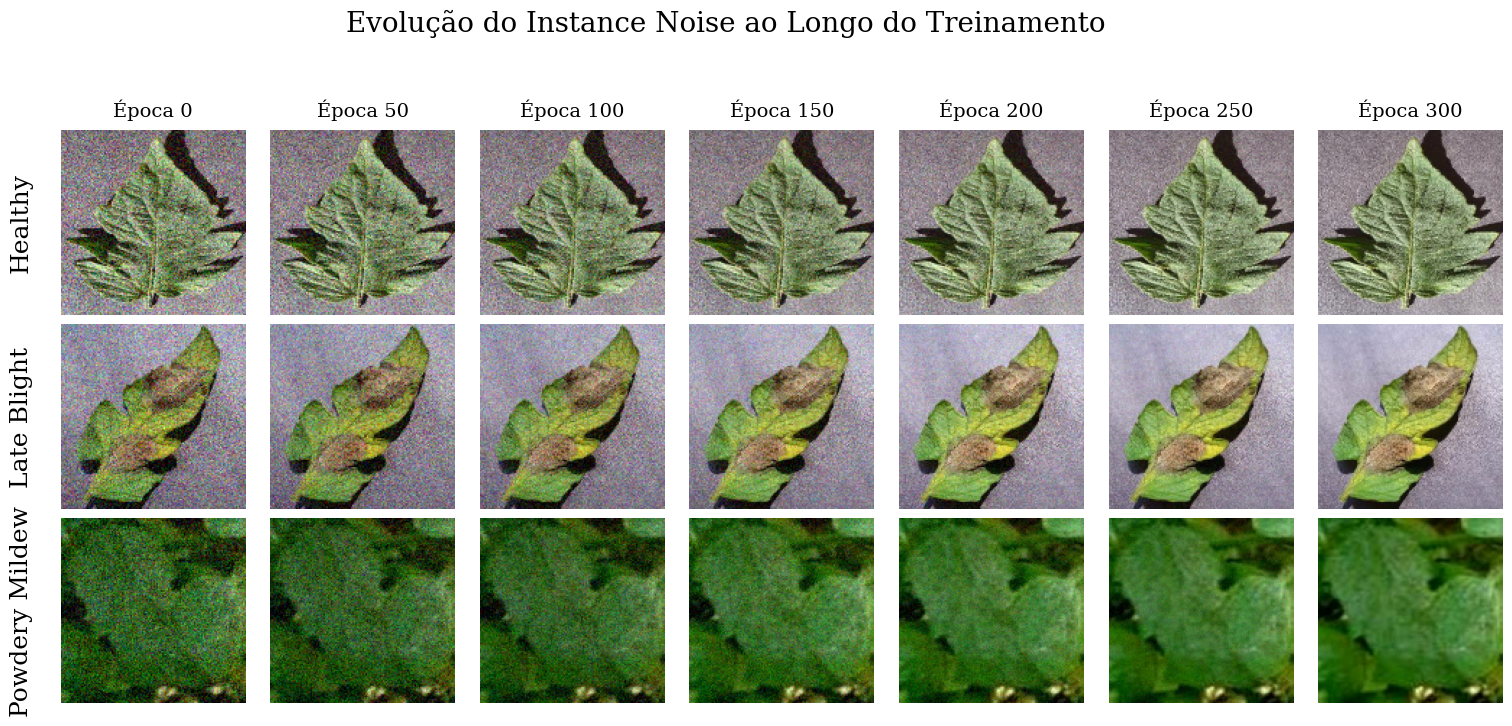


✔ Gráfico acadêmico exportado com sucesso em: /content/drive/MyDrive/TCC_DCGAN/images_to_plot/grid_instance_noise_matplotlib.png


In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# --- Configurações ---
diretorio = '/content/drive/MyDrive/TCC_DCGAN/images_to_plot'
classes_base = ['healthy', 'Late_Blight', 'powdery_mildew']
epocas = list(range(0, 301, 50))

# Configuração da figura acadêmica
plt.rcParams['font.family'] = 'serif'
fig, axes = plt.subplots(nrows=len(classes_base), ncols=len(epocas), figsize=(16, 7))

# Título Principal
fig.suptitle("Evolução do Instance Noise ao Longo do Treinamento", fontsize=20, y=1.05)

# --- Montagem do Grid ---
for i, classe in enumerate(classes_base):
    for j, epoca in enumerate(epocas):
        ax = axes[i, j]
        ax.axis('off') # Remove os eixos numéricos

        # Constrói o caminho exato do arquivo
        nome_arquivo = f"{classe}_epoca_{epoca:03d}.png"
        caminho_imagem = os.path.join(diretorio, nome_arquivo)

        # Carrega e plota a imagem
        try:
            img = mpimg.imread(caminho_imagem)
            ax.imshow(img)
        except FileNotFoundError:
            print(f"Aviso: Imagem não encontrada - {nome_arquivo}")

        # 1. Adiciona os títulos das colunas (Épocas) apenas na primeira linha
        if i == 0:
            ax.set_title(f"Época {epoca}", fontsize=14, pad=10)

        # 2. Adiciona os nomes das classes apenas na primeira coluna (Lado Esquerdo)
        if j == 0:
            # Formata o nome para exibição (ex: 'Late Blight')
            nome_exibicao = classe.replace('_', ' ').title()

            ax.text(-0.15, 0.5, nome_exibicao,
                    transform=ax.transAxes,
                    fontsize=18,          # Fonte aumentada
                    fontweight='normal',  # Sem negrito
                    va='center',          # Alinhamento vertical centralizado com a imagem
                    ha='right',           # Alinhamento horizontal à direita (encostando na imagem)
                    rotation=90)          # Rotaciona para leitura vertical

# --- Ajuste de Espaçamento e Exportação ---
# O rect garante que o tight_layout não corte o título principal (suptitle)
plt.tight_layout(rect=[0, 0, 1, 1])

# Dá um respiro na margem esquerda para o texto rotacionado não ser cortado
plt.subplots_adjust(left=0.08, wspace=0.05, hspace=0.05)

caminho_salvar = os.path.join(diretorio, "grid_instance_noise_matplotlib.png")
plt.savefig(caminho_salvar, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✔ Gráfico acadêmico exportado com sucesso em: {caminho_salvar}")